# Task 1: Iris Flower Classification
**Objective:** Train ML classifiers to predict the iris species (Setosa, Versicolor, Virginica) from its measurements.

**Tech stack:** Python, pandas, scikit-learn, matplotlib, seaborn

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style='whitegrid')

## 2. Load the Dataset
The Iris dataset is built into scikit-learn, so no download is needed.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
df = df.drop(columns='target')
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory Data Analysis (EDA)

In [3]:
print('Shape:', df.shape)
print('\nData types:')
print(df.dtypes)
print('\nNull values per column:')
print(df.isnull().sum())
print('\nClass distribution:')
print(df['species'].value_counts())

Shape: (150, 5)

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                  str
dtype: object

Null values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


**Observations:** The dataset has 150 rows and 4 numeric features with no missing values. The three classes are perfectly balanced (50 samples each), so accuracy is a fair metric here.

## 4. Visualisations

### 4.1 Pairplot (feature distributions by species)

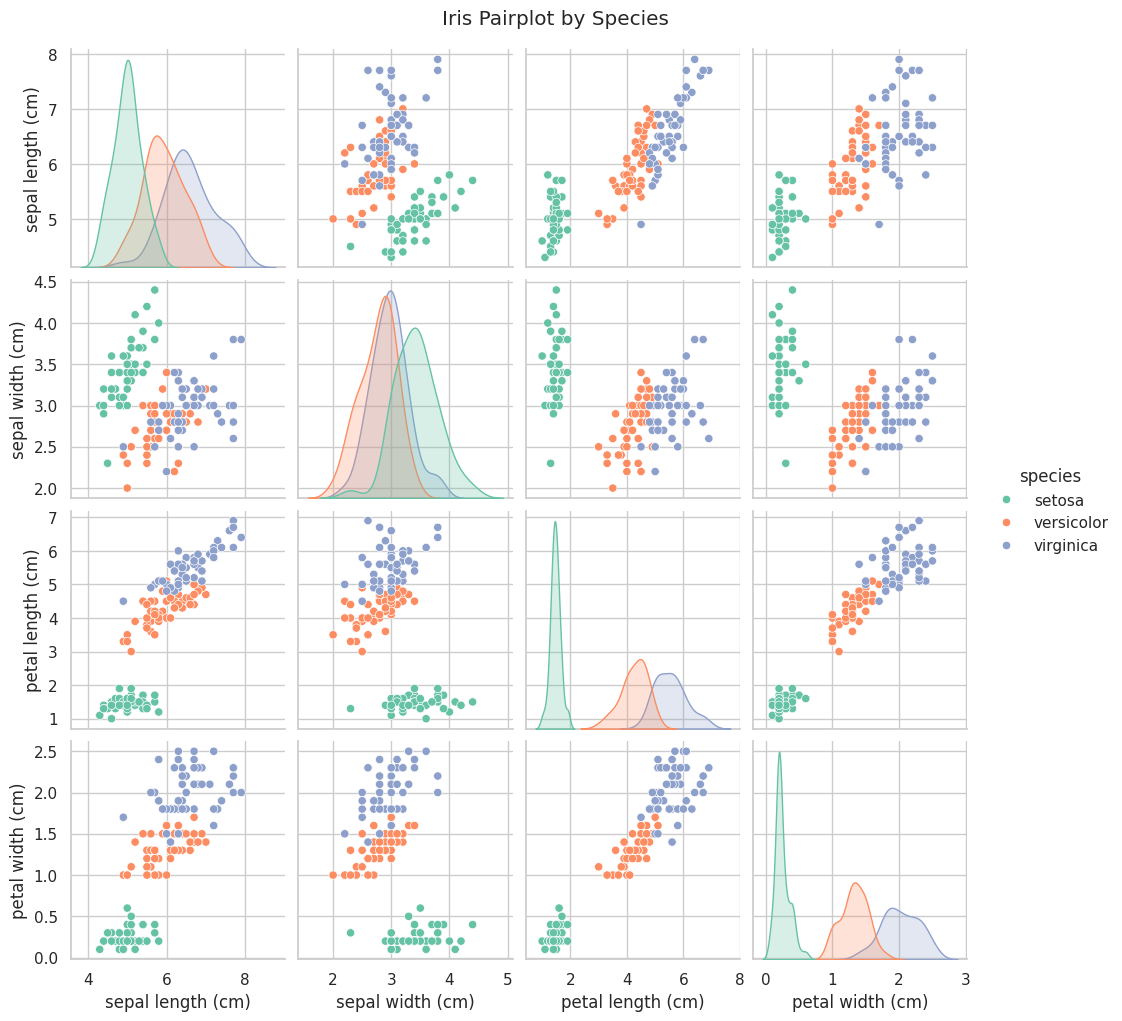

In [5]:
sns.pairplot(df, hue='species', palette='Set2', diag_kind='kde')
plt.suptitle('Iris Pairplot by Species', y=1.02)
plt.show()

### 4.2 Box plots for each feature

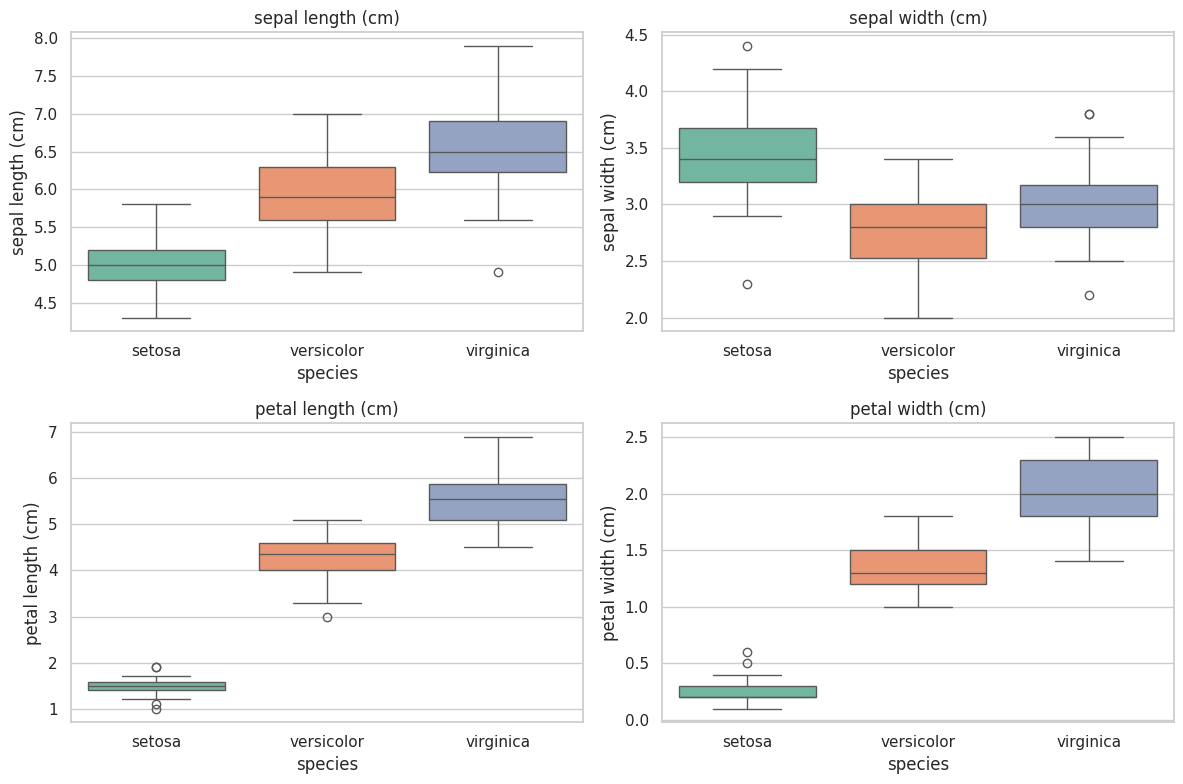

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), iris.feature_names):
    sns.boxplot(data=df, x='species', y=col, hue='species', palette='Set2', legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 5. Feature Selection Discussion
Which features separate the species best?

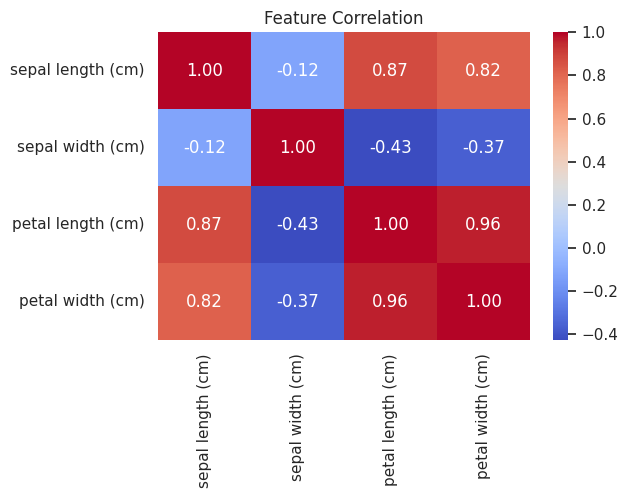

            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                              
setosa                   5.01              3.43               1.46   
versicolor               5.94              2.77               4.26   
virginica                6.59              2.97               5.55   

            petal width (cm)  
species                       
setosa                  0.25  
versicolor              1.33  
virginica               2.03  


In [7]:
corr = df[iris.feature_names].corr()
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation')
plt.show()

print(df.groupby('species')[iris.feature_names].mean().round(2))

**Discussion:**
- **Petal length** and **petal width** are the most discriminative features. Setosa is completely separated from the other two species using petals alone, and Versicolor and Virginica overlap only slightly.
- **Sepal width** is the least discriminative, with heavy overlap between species.
- Petal length and petal width are highly correlated, so they carry similar information. A model could use just these two and still perform very well.

## 6. Train/Test Split (80/20)
We use `stratify=y` so each class keeps the same proportion in both sets.

In [8]:
X = df[iris.feature_names]
y = df['species']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train size:', X_train.shape[0], '| Test size:', X_test.shape[0])

Train size: 120 | Test size: 30


## 7. Train and Evaluate Models
We train four classifiers: Logistic Regression, K-Nearest Neighbours, Decision Tree and Random Forest.

Logistic Regression | Accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



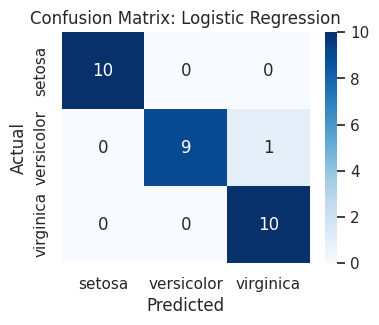

K-Nearest Neighbours | Accuracy: 1.0
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



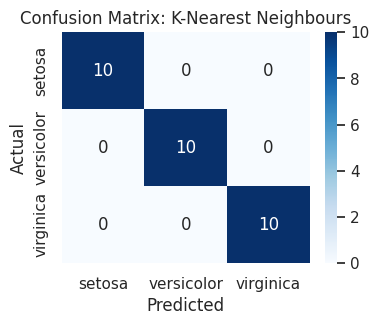

Decision Tree | Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



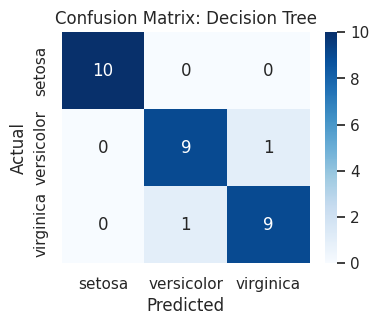

Random Forest | Accuracy: 0.9
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



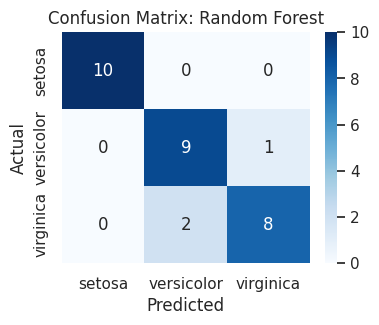

In [9]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=200),
    'K-Nearest Neighbours': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    results[name] = acc

    print('=' * 60)
    print(name, '| Accuracy:', round(acc, 4))
    print('=' * 60)
    print(classification_report(y_test, pred))

    cm = confusion_matrix(y_test, pred, labels=iris.target_names)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.show()

## 8. Model Comparison

K-Nearest Neighbours    1.0000
Logistic Regression     0.9667
Decision Tree           0.9333
Random Forest           0.9000
dtype: float64


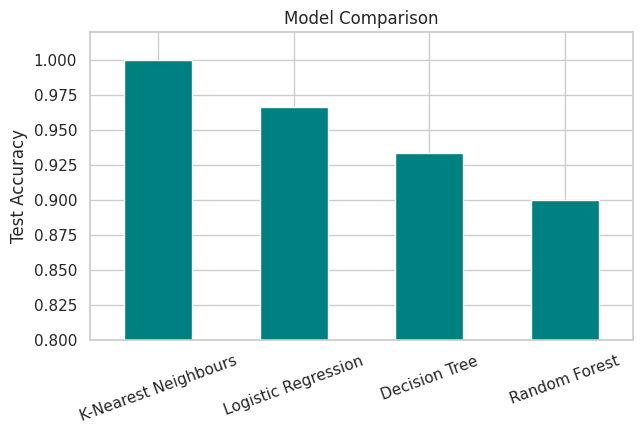

In [10]:
res = pd.Series(results).sort_values(ascending=False)
print(res.round(4))
res.plot(kind='bar', color='teal', figsize=(7, 4), ylim=(0.8, 1.02))
plt.ylabel('Test Accuracy'); plt.title('Model Comparison')
plt.xticks(rotation=20)
plt.show()

## 9. Cross-Validation (more reliable comparison)
The test set has only 30 samples, so one misclassification changes accuracy by about 3%. 5-fold cross-validation gives a more stable estimate.

In [11]:
from sklearn.model_selection import cross_val_score
cv = {n: cross_val_score(m, X, y, cv=5).mean() for n, m in models.items()}
cv = pd.Series(cv).sort_values(ascending=False)
print(cv.round(4))

Logistic Regression     0.9733
K-Nearest Neighbours    0.9733
Random Forest           0.9667
Decision Tree           0.9533
dtype: float64


## 10. Conclusion: Best Model

| Model | Test Accuracy (80/20) | 5-Fold CV Accuracy |
|---|---|---|
| K-Nearest Neighbours | 1.0000 | 0.9733 |
| Logistic Regression | 0.9667 | 0.9733 |
| Decision Tree | 0.9333 | 0.9533 |
| Random Forest | 0.9000 | 0.9667 |

**Best model: K-Nearest Neighbours (k=5).** It got 100% on the test split (no misclassifications) and tied for the top cross-validated score (97.33%) with Logistic Regression. Since the test set has only 30 samples, the cross-validation score is the more reliable measure, and it shows KNN and Logistic Regression are essentially equal. KNN is chosen because it was perfect on the held-out test set.

**Key takeaways:**
1. Petal length and petal width are the strongest predictors of species.
2. Setosa is always classified correctly. Any errors are between Versicolor and Virginica.
3. Even simple models perform very well, so the classes are almost linearly separable.
4. Random Forest scored lowest on this one split, but that is just the luck of a 30-sample test set. Its cross-validated score (96.7%) is close to the others.